Integrantes:

Fernanda Waltrs Freitas - (email: fernandawaltrsf@usp.br | Nº USP: 11857319)

Luiz Venâncio Jaldin de Oliveira - (email: luiz.jaldin@gmail.com | Nº USP: 10408601)

Kaique Antunes dos Santos - (email: kaiqueas@usp.br.com | Nº USP: 17440420)


# Otimização de uma Carteira de Crédito utilizando Programação Linear

### Fontes utilizadas

- **Pré-projeto:** *Otimização de Carteira de Crédito utilizando Programação Linear*. O documento propõe um modelo de Programação Linear para maximizar o retorno esperado da carteira, utilizando taxas de juros, spread e inadimplência, com restrições de risco, limites de investimento, alocação total e retorno mínimo.
- **Paper de referência:** Ribeiro et al. (2022), *Otimização de uma Carteira de Crédito utilizando Programação Linear e Análise de Sensibilidade*.
- O Banco do Brasil (BB) é uma das principais instituições financeiras do Brasil e possui atuação em diversos segmentos do mercado bancário, oferecendo produtos e serviços para pessoas físicas, empresas e produtores rurais. Fundado em 1808, o banco possui uma ampla presença no território nacional e desempenha um papel relevante no sistema financeiro brasileiro. Para o desenvolvimento deste trabalho, foram utilizados dados relacionados às operações de crédito do Banco do Brasil PF, considerando informações como taxas de juros, inadimplência e retorno das modalidades de crédito. A utilização desses dados permite representar de forma mais próxima da realidade o cenário de concessão de crédito e fornecer parâmetros para a aplicação do modelo de otimização desenvolvido no trabalho.


### Escopo

O notebook seguirá o escopo do pré-projeto e utilizará o paper como referência para a formulação. O fluxo será:

1. contextualização do problema;
2. geração e preparação de dados reais;
3. construção dos indicadores;
4. formulação matemática;
5. otimização por Programação Linear;
6. interpretação e validação dos resultados;
7. conclusão e preparação para substituição pela base real.




## 1. Contextualização e definição do problema

O problema consiste em decidir **quanto dos recursos disponíveis deve ser alocado em cada modalidade de crédito**, buscando maximizar o retorno esperado da carteira sem ultrapassar um nível máximo de risco.

A variável de decisão será a proporção dos recursos destinada a cada modalidade e estabelecer como objetivo maximizar o retorno esperado da carteira. Entre as restrições previstas estão o limite máximo de inadimplência, os limites mínimo e máximo por modalidade, a alocação total dos recursos e um retorno mínimo esperado.

O paper de referência utiliza 7 modalidades de pessoa física encontrado em [referência](https://view.officeapps.live.com/op/view.aspx?src=https%3A%2F%2Fapi.mziq.com%2Fmzfilemanager%2Fv2%2Fd%2F5760dff3-15e1-4962-9e81-322a0b3d0bbd%2F487685c8-8eaf-b348-c53f-2e97b6aa2a86%3Forigin%3D2&wdOrigin=BROWSELINK):

- 1: Crédito Consignado
- 2: Crédito Não Consignado
- 3: Financiamento Imobiliário
- 4: Financiamento de Veículos
- 5: Cartão de Crédito
- 6: Cheque Especial
- 7: Microcrédito


### Premissas numéricas

Nesse projeto vamos ter as seguintes restrições no final de 2025:

- **risco máximo:**  6,56% de inadimplência [Página 34](https://api.mziq.com/mzfilemanager/v2/d/5760dff3-15e1-4962-9e81-322a0b3d0bbd/d5cc4a23-02fc-0da7-d17a-b414a1e56095?origin=2);
- **retorno mínimo:** CAPM de  19,28% a.a.; (Calculado abaixo)
- **alocação mínima:** 3% por modalidade (definido pelos autores);
- **alocação máxima:** 30% por modalidade (definido pelos autores).

O paper calcula o CAPM com (Ibovespa/B3 [Link site](https://www.b3.com.br/pt_br/market-data-e-indices/indices/indices-amplos/indice-ibovespa-ibovespa-estatisticas-historicas.htm) )`Rf = 33,95%`, (B3 ou bases de mercado como Yahoo Finance, Investing [Link site](https://br.investing.com/pro/BOVESPA:BBAS3/explorer/beta) )`β = 0,23` e (taxa livre de risco (Selic) [Link site](https://www.bcb.gov.br/controleinflacao/historicotaxasjuros) ) `Rm = 14,90%`, resultando em 19,28% a.a. A fórmula utilizada é:

$$
K_e = R_f + \beta(R_m - R_f)
$$

Onde:

- $K_e$ = custo de capital próprio (CAPM);
- $R_f$ = taxa livre de risco;
- $\beta$ = beta da ação BBAS3;
- $R_m$ = retorno esperado do mercado;
- $(R_m - R_f)$ = prêmio de risco de mercado.

Para o cálculo, foram considerados os seguintes valores:

- **Taxa Selic:** $R_f = 14,90\%$
- **Beta do BBAS3:** $\beta = 0,23$
- **Retorno do Ibovespa:** $R_m = 33,95\%$

### 1. Cálculo do prêmio de risco

$$
R_m - R_f = 33,95\% - 14,90\%
$$

$$
R_m - R_f = 19,05\%
$$

### 2. Cálculo do CAPM

Substituindo os valores na fórmula:

$$
K_e = 14,90\% + 0,23(33,95\% - 14,90\%)
$$

$$
K_e = 14,90\% + 0,23(19,05\%)
$$

$$
K_e = 14,90\% + 4,3815\%
$$

Portanto:

$$
\boxed{K_e = 19,2815\% \text{ a.a.}}
$$

A formulação será implementada com variáveis contínuas de proporção, de modo que:

$$
0{,}03 \leq p_i \leq 0{,}30
$$
e
$$
\sum_i p_i = 1.
$$

In [ ]:
from dataclasses import dataclass
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linprog
from IPython.display import display

@dataclass(frozen=True)
class ModelConfig:
    risk_max_pct: float = 6.56
    min_allocation: float = 0.03
    max_allocation: float = 0.30
    rf_pct: float = 14.90
    beta: float = 0.23
    rm_pct: float = 33.95
    start_date: str = "2025-01-01"
    end_date: str = "2025-12-31"

    @property
    def capm_pct(self) -> float:
        return self.rf_pct + self.beta * (self.rm_pct - self.rf_pct)

CONFIG = ModelConfig()

MODALIDADES = [
    "Crédito Consignado"
    ,"Crédito Não Consignado"
    ,"Financiamento Imobiliário"
    ,"Financiamento de Veículos"
    ,"Cartão de Crédito"
    ,"Cheque Especial"
    ,"Microcrédito"
]

print(f"CAPM de referência: {CONFIG.capm_pct:.2f}% a.a.")
print(f"Risco máximo: {CONFIG.risk_max_pct:.2f}%")
print(f"Limites por modalidade: {CONFIG.min_allocation:.0%} a {CONFIG.max_allocation:.0%}")


CAPM de referência: 19.28% a.a.
Risco máximo: 6.56%
Limites por modalidade: 3% a 30%



## 2. Geração e preparação dos dados

Variáveis relevantes do problema:

- `taxa_juros_aa`: taxa média anualizada da modalidade;
- `selic_aa`: taxa básica utilizada como custo de referência para a captação;
- `spread_aa`: diferença entre a taxa da modalidade e a SELIC;
- `inadimplencia_pct`: percentual sintético de inadimplência baseado em [Link](https://dadosabertos.bcb.gov.br/dataset/21113-inadimplencia-da-carteira-de-credito-com-recursos-livres---pessoas-fisicas---cheque-especial).


### Consulta a API do Bancon Central para coleta de dados

In [ ]:
import requests

In [ ]:
def load_selic_data(ano=2025):
    """Carrega a meta Selic do Banco Central e retorna um dicionário mensal."""

    url = "https://api.bcb.gov.br/dados/serie/bcdata.sgs.432/dados/"

    params = {
        "formato": "json",
        "dataInicial": f"01/01/{ano}",
        "dataFinal": f"31/12/{ano}"
    }

    response = requests.get(url, params=params, timeout=30)
    response.raise_for_status()

    df = pd.DataFrame(response.json())

    if df.empty:
        raise ValueError(f"Nenhum dado da Selic encontrado para {ano}.")

    df["data"] = pd.to_datetime(df["data"], dayfirst=True)
    df["valor"] = pd.to_numeric(df["valor"], errors="raise")

    df = df.set_index("data").sort_index()

    # Propaga a última meta conhecida pelos dias sem observação.
    calendario = pd.date_range(
        start=f"{ano}-01-01",
        end=f"{ano}-12-31",
        freq="D"
    )

    df = df.reindex(calendario).ffill()

    # Recupera a taxa vigente no primeiro dia de cada mês.
    mensal = df["valor"].resample("MS").first()

    if mensal.isna().any():
        raise ValueError("Existem meses sem uma taxa Selic válida.")

    return {
        data.strftime("%Y-%m"): float(valor)
        for data, valor in mensal.items()
    }


In [ ]:
def load_credit_rates(series_map, year=2025, month=12):
    """
    Consulta séries SGS do Banco Central e retorna
    as taxas referentes ao mês solicitado.

    series_map: dicionário {nome_modalidade: codigo_sgs}
    """

    data_inicio = f"01/{month:02d}/{year}"
    ultimo_dia = pd.Period(
        f"{year}-{month:02d}"
    ).days_in_month
    data_fim = f"{ultimo_dia:02d}/{month:02d}/{year}"

    taxas = {}

    for modalidade, codigo in series_map.items():
        url = (
            "https://api.bcb.gov.br/dados/serie/"
            f"bcdata.sgs.{codigo}/dados/"
        )

        response = requests.get(
            url,
            params={
                "formato": "json",
                "dataInicial": data_inicio,
                "dataFinal": data_fim,
            },
            timeout=60,
        )
        response.raise_for_status()

        dados = response.json()

        if not dados:
            raise ValueError(
                f"Sem dados para {modalidade} "
                f"em {month:02d}/{year} (SGS {codigo})."
            )

        df = pd.DataFrame(dados)
        df["valor"] = pd.to_numeric(
            df["valor"], errors="raise"
        )

        # Para séries mensais, deve existir uma observação
        # referente ao mês consultado.
        taxas[modalidade] = float(df.iloc[-1]["valor"])

    return taxas


### Montagem da base com os indicadores de crédito

In [ ]:
mudanca_selic=1
def generate_synthetic_credit_data(config: ModelConfig) -> pd.DataFrame:
    """Gera uma base mensal para as modalidades de crédito."""

    dates = pd.date_range(config.start_date, config.end_date, freq="MS")

    # ============================================================
    # TRAJETÓRIA DA SELIC EM 2025
    # ============================================================

    anchor_map = load_selic_data(2025)

    anchor_dates = pd.to_datetime(list(anchor_map.keys()))
    anchor_values = np.array(list(anchor_map.values()))

    selic = np.interp(
        dates.astype("int64"),
        anchor_dates.astype("int64"),
        anchor_values
    )

    # ============================================================
    # TAXA DE JUROS POR MODALIDADE
    # ============================================================

    series_map = {
            "Crédito Consignado": 20747,
            "Crédito Não Consignado": 20742,
            "Financiamento Imobiliário": 20774,
            "Financiamento de Veículos": 20749,
            "Cartão de Crédito": 22024,
            "Cheque Especial": 20741,
            "Microcrédito": 20782,
        }

    taxa_base = load_credit_rates(
                              series_map,
                              year=2025,
                              month=12)

    # ============================================================
    # INADIMPLÊNCIA POR MODALIDADE
    # Valores em %
    # ============================================================

    series_map = {
            "Crédito Consignado": 21119,
            "Crédito Não Consignado": 21114,
            "Financiamento Imobiliário": 21151,
            "Financiamento de Veículos": 21121,
            "Cartão de Crédito": 21129,
            "Cheque Especial": 21113,
            "Microcrédito": 21159}

    inadimplencia_base = load_credit_rates(
                                    series_map,
                                    year=2025,
                                    month=12)

    rows = []

    for t, date in enumerate(dates):

        for modalidade in MODALIDADES:

            # ====================================================
            # TAXA DE JUROS DO PRODUTO
            # Mantida exatamente como informada em taxa_base
            # ====================================================

            taxa_juros = taxa_base[modalidade]

            # ====================================================
            # SPREAD
            # ====================================================

            spread = taxa_juros - selic[t] * mudanca_selic

            # ====================================================
            # INADIMPLÊNCIA
            # Valor específico para cada modalidade
            # ====================================================

            inadimplencia = inadimplencia_base[modalidade]

            # ====================================================
            # ARMAZENAMENTO
            # ====================================================

            rows.append({
                "data": date,
                "modalidade": modalidade,
                "selic_aa": selic[t],
                "taxa_juros_aa": taxa_juros,
                "spread_aa": spread,
                "inadimplencia_pct": inadimplencia,
            })

    return pd.DataFrame(rows)


# ================================================================
# GERAÇÃO DA BASE
# ================================================================

df = generate_synthetic_credit_data(CONFIG)

print("Base sintética criada.")

df_info = df.shape
linhas = df_info[0]
colunas = df_info[1]

print(f"Linhas: {linhas}")
print(f"Colunas: {colunas}")
print(f"Período: {df['data'].min():%m/%Y} a {df['data'].max():%m/%Y}")

display(df.head(10))

Base sintética criada.
Linhas: 84
Colunas: 6
Período: 01/2025 a 12/2025


,data,modalidade,selic_aa,taxa_juros_aa,spread_aa,inadimplencia_pct
0,2025-01-01,Crédito Consignado,12.25,27.16,14.91,2.81
1,2025-01-01,Crédito Não Consignado,12.25,116.59,104.34,9.16
2,2025-01-01,Financiamento Imobiliário,12.25,10.78,-1.47,1.06
3,2025-01-01,Financiamento de Veículos,12.25,26.44,14.19,5.69
4,2025-01-01,Cartão de Crédito,12.25,89.18,76.93,8.89
5,2025-01-01,Cheque Especial,12.25,138.89,126.64,17.33
6,2025-01-01,Microcrédito,12.25,48.82,36.57,4.95
7,2025-02-01,Crédito Consignado,13.25,27.16,13.91,2.81
8,2025-02-01,Crédito Não Consignado,13.25,116.59,103.34,9.16
9,2025-02-01,Financiamento Imobiliário,13.25,10.78,-2.47,1.06


In [ ]:
# Validação de campos
required_columns = {
    "data", "modalidade", "selic_aa", "taxa_juros_aa",
    "spread_aa", "inadimplencia_pct"
}

assert required_columns.issubset(df.columns), "Existem colunas obrigatórias ausentes."
assert df["data"].notna().all(), "Existem datas ausentes."
assert df["modalidade"].notna().all(), "Existem modalidades ausentes."
assert df[["selic_aa", "taxa_juros_aa", "spread_aa", "inadimplencia_pct"]].notna().all().all(),     "Existem valores numéricos ausentes."
assert (df["taxa_juros_aa"] > 0).all(), "Existem taxas de juros não positivas."
assert (df["inadimplencia_pct"] >= 0).all(), "Existem inadimplências negativas."

spread_recalculado = df["taxa_juros_aa"] - df["selic_aa"]
assert np.allclose(df["spread_aa"], spread_recalculado),     "A relação entre taxa, SELIC e spread não está consistente."

print("Todas as validações iniciais foram aprovadas.")

Todas as validações iniciais foram aprovadas.


In [ ]:
display(
    df.groupby("modalidade")[
        ["taxa_juros_aa", "selic_aa", "spread_aa", "inadimplencia_pct"]
    ]
    .agg(["mean", "std", "min", "max"])
    .round(2)
)

print("Observação: os valores acima são simulados e servem apenas para a reprodução metodológica.")


taxa_juros_aa                      selic_aa        \
                                   mean  std     min     max     mean   std   
modalidade                                                                    
Cartão de Crédito                 89.18  0.0   89.18   89.18    14.33  0.93   
Cheque Especial                  138.89  0.0  138.89  138.89    14.33  0.93   
Crédito Consignado                27.16  0.0   27.16   27.16    14.33  0.93   
Crédito Não Consignado           116.59  0.0  116.59  116.59    14.33  0.93   
Financiamento Imobiliário         10.78  0.0   10.78   10.78    14.33  0.93   
Financiamento de Veículos         26.44  0.0   26.44   26.44    14.33  0.93   
Microcrédito                      48.82  0.0   48.82   48.82    14.33  0.93   

                                       spread_aa                        \
                             min   max      mean   std     min     max   
modalidade                                                               
Cartão de Crédito          12.25  15.0     74.85  0.93   74.18   76.93   
Cheque Especial            12.25  15.0    124.56  0.93  123.89  126.64   
Crédito Consignado         12.25  15.0     12.83  0.93   12.16   14.91   
Crédito Não Consignado     12.25  15.0    102.26  0.93  101.59  104.34   
Financiamento Imobiliário  12.25  15.0     -3.55  0.93   -4.22   -1.47   
Financiamento de Veículos  12.25  15.0     12.11  0.93   11.44   14.19   
Microcrédito               12.25  15.0     34.49  0.93   33.82   36.57   

                          inadimplencia_pct                     
                                       mean  std    min    max  
modalidade                                                      
Cartão de Crédito                      8.89  0.0   8.89   8.89  
Cheque Especial                       17.33  0.0  17.33  17.33  
Crédito Consignado                     2.81  0.0   2.81   2.81  
Crédito Não Consignado                 9.16  0.0   9.16   9.16  
Financiamento Imobiliário              1.06  0.0   1.06   1.06  
Financiamento de Veículos              5.69  0.0   5.69   5.69  
Microcrédito                           4.95  0.0   4.95   4.95

Observação: os valores acima são simulados e servem apenas para a reprodução metodológica.



### Visualização das séries sintéticas

A primeira visualização mostra como o spread se comporta ao longo do tempo. Como a taxa de crédito é construída a partir da SELIC mais um spread específico da modalidade, o spread apresenta comportamento mais estável que a taxa absoluta.

Essa distinção é importante porque o paper argumenta que o spread é uma medida mais adequada do retorno da operação para a formulação do problema.


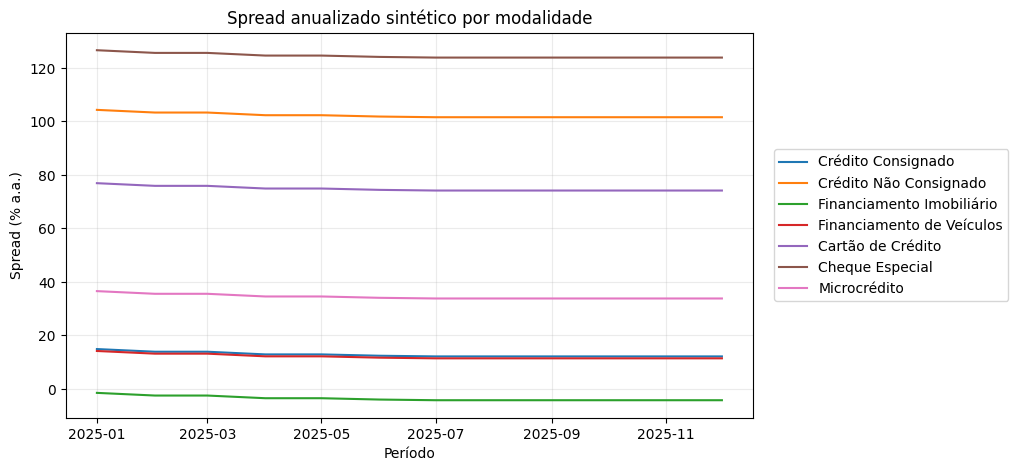

In [ ]:
fig, ax = plt.subplots(figsize=(11, 5))

for modalidade in MODALIDADES:
    temp = df[df["modalidade"] == modalidade]
    ax.plot(temp["data"], temp["spread_aa"], label=modalidade)

ax.set_title("Spread anualizado sintético por modalidade")
ax.set_xlabel("Período")
ax.set_ylabel("Spread (% a.a.)")

# Legenda fora do gráfico, à direita
ax.legend(
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    frameon=True
)

ax.grid(alpha=0.25)

# Reserva espaço para a legenda
fig.subplots_adjust(right=0.75)

plt.show()


## 3. Construção dos indicadores

O paper utiliza o **spread** como medida de retorno e a **inadimplência** como medida de risco.

### Retorno

Para cada modalidade, o retorno esperado utilizado no modelo será a média do spread observado no período:

$$
r_i = rac{1}{T}\sum_{t=1}^{T} spread_{i,t}
$$

onde:

- \(r_i\) é o retorno esperado da modalidade \(i\);
- \(spread_{i,t}\) é o spread observado para a modalidade \(i\) no mês \(t\);
- \(T\) é o número de meses observados.

### Risco

De forma análoga, o risco de cada modalidade será representado pela média da inadimplência observada:

$$
q_i = rac{1}{T}\sum_{t=1}^{T} inadimplência_{i,t}
$$

O risco da carteira será a média ponderada desses riscos:

$$
R_{carteira} = \sum_i p_i q_i
$$

Essa estrutura reproduz a lógica descrita no paper: a composição da carteira determina simultaneamente seu retorno e sua exposição média à inadimplência.

O modelo de otimização utilizará somente esses indicadores agregados por modalidade. A série mensal permanecerá como base de cálculo e auditoria.


In [ ]:

def build_model_parameters(df: pd.DataFrame) -> pd.DataFrame:
    """Agrega a série temporal e produz os parâmetros utilizados no LP."""
    parameters = (
        df.groupby("modalidade", as_index=False)
        .agg(
            retorno_esperado_aa=("spread_aa", "mean"),
            risco_inadimplencia_pct=("inadimplencia_pct", "mean"),
            taxa_juros_media_aa=("taxa_juros_aa", "mean"),
        )
    )
    return parameters.set_index("modalidade").loc[MODALIDADES].reset_index()

parameters = build_model_parameters(df)

assert parameters["retorno_esperado_aa"].notna().all()
assert parameters["risco_inadimplencia_pct"].notna().all()
assert (parameters["risco_inadimplencia_pct"] >= 0).all()

display(parameters.round(3))


,modalidade,retorno_esperado_aa,risco_inadimplencia_pct,taxa_juros_media_aa
0,Crédito Consignado,12.827,2.81,27.16
1,Crédito Não Consignado,102.257,9.16,116.59
2,Financiamento Imobiliário,-3.553,1.06,10.78
3,Financiamento de Veículos,12.107,5.69,26.44
4,Cartão de Crédito,74.847,8.89,89.18
5,Cheque Especial,124.557,17.33,138.89
6,Microcrédito,34.487,4.95,48.82


Nesse gráfico quanto mais a direita uma modalidade estiver maior o risco de inadimplência.
E quanto mais alto maior o retorno esperado.


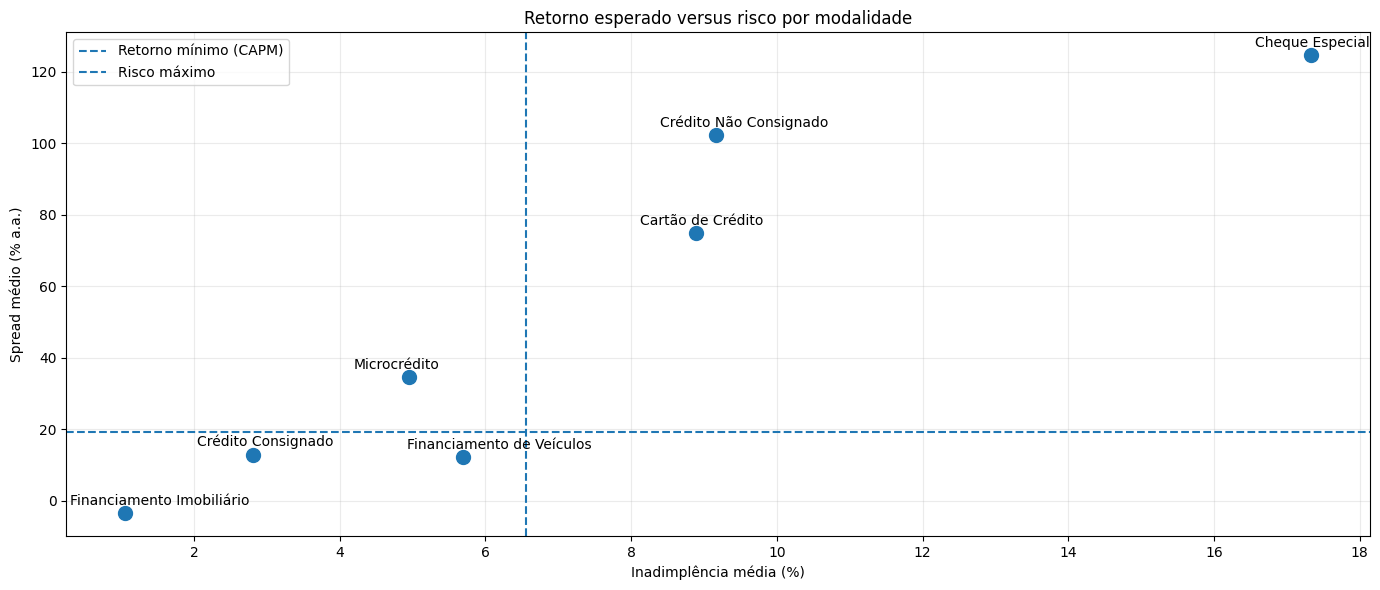

In [ ]:
print("Nesse gráfico quanto mais a direita uma modalidade estiver maior o risco de inadimplência.")
print("E quanto mais alto maior o retorno esperado.")
fig, ax = plt.subplots(figsize=(14, 6))

ax.scatter(
    parameters["risco_inadimplencia_pct"],
    parameters["retorno_esperado_aa"],
    s=100
)

for _, row in parameters.iterrows():
    ax.annotate(
        row["modalidade"],
        (row["risco_inadimplencia_pct"], row["retorno_esperado_aa"]),
        xytext=(-40, 6),
        textcoords="offset points"
    )

ax.axhline(CONFIG.capm_pct, linestyle="--", linewidth=1.5, label="Retorno mínimo (CAPM)")
ax.axvline(CONFIG.risk_max_pct, linestyle="--", linewidth=1.5, label="Risco máximo")

ax.set_title("Retorno esperado versus risco por modalidade")
ax.set_xlabel("Inadimplência média (%)")
ax.set_ylabel("Spread médio (% a.a.)")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()



## 4. Formulação matemática

Seja \(I\) o conjunto das modalidades de crédito e seja:

$$
p_i = 	ext{proporção da carteira alocada na modalidade } i
$$

e:

$$
r_i = 	ext{retorno esperado da modalidade } i
$$

$$
q_i = 	ext{risco de inadimplência da modalidade } i
$$

### Função objetivo

Maximizar o retorno esperado da carteira:

$$
oxed{
\max Z = \sum_{i \in I} p_i r_i
}
$$

### Restrições

**1. Alocação total**

$$
oxed{
\sum_{i \in I} p_i = 1
}
$$

**2. Limite máximo de risco**

$$
oxed{
\sum_{i \in I} p_i q_i \leq 6,56\%
}
$$

**3. Retorno mínimo**

$$
oxed{
\sum_{i \in I} p_i r_i \geq 10{,}68\%
}
$$

**4. Limite mínimo por modalidade**

$$
oxed{
p_i \geq 0{,}03 \quad orall i
}
$$

**5. Limite máximo por modalidade**

$$
oxed{
p_i \leq 0{,}30 \quad orall i
}
$$

### Observação sobre o paper

O paper também apresenta uma restrição adicional relacionada à destinação de recursos de poupança para crédito rural e imobiliário. Essa restrição **não será incorporada nesta reprodução**, porém problema continua sendo um problema de Programação Linear: tanto a função objetivo quanto todas as restrições são combinações lineares das variáveis \(p_i\).


In [ ]:
def solve_credit_portfolio(parameters: pd.DataFrame, config: ModelConfig):
    """Resolve o problema de alocação da carteira por Programação Linear."""
    returns = parameters["retorno_esperado_aa"].to_numpy()
    risks = parameters["risco_inadimplencia_pct"].to_numpy()
    n = len(parameters)

    # linprog minimiza por padrão; por isso usamos -retorno.
    c = -returns

    # A_ub @ x <= b_ub
    A_ub = np.vstack([
        risks,      # risco <= limite
        -returns,   # -retorno <= -retorno_mínimo
    ])
    b_ub = np.array([
        config.risk_max_pct,
        -config.capm_pct,
    ])

    # Soma das alocações = 100%.
    A_eq = np.ones((1, n))
    b_eq = np.array([1.0])

    bounds = [
        (config.min_allocation, config.max_allocation)
        for _ in range(n)
    ]

    return linprog(
        c=c,
        A_ub=A_ub,
        b_ub=b_ub,
        A_eq=A_eq,
        b_eq=b_eq,
        bounds=bounds,
        method="highs-ds",  # Dual Simplex
    )

result = solve_credit_portfolio(parameters, CONFIG)

print("Status do solver:", result.message)
assert result.success, "O problema não encontrou uma solução factível."

print(f"Valor da função objetivo: {-result.fun:.4f}% a.a.")


Status do solver: Optimization terminated successfully. (HiGHS Status 7: Optimal)
Valor da função objetivo: 56.9024% a.a.


In [ ]:
def build_solution_table(parameters: pd.DataFrame, solution: np.ndarray) -> pd.DataFrame:
    """Organiza a solução ótima em formato auditável."""
    out = parameters.copy()
    out["alocacao_otima"] = solution
    out["alocacao_otima_pct"] = solution * 100
    out["contrib_retorno_pct"] = solution * out["retorno_esperado_aa"]
    out["contrib_risco_pct"] = solution * out["risco_inadimplencia_pct"]
    return out

solution_df = build_solution_table(parameters, result.x)

portfolio_return = solution_df["contrib_retorno_pct"].sum()
portfolio_risk = solution_df["contrib_risco_pct"].sum()

display(
    solution_df[
        [
            "modalidade",
            "retorno_esperado_aa",
            "risco_inadimplencia_pct",
            "alocacao_otima_pct",
            "contrib_retorno_pct",
            "contrib_risco_pct",
        ]
    ].round(3)
)

print(f"Retorno da carteira: {portfolio_return:.3f}% a.a.")
print(f"Risco da carteira: {portfolio_risk:.3f}%")


,modalidade,retorno_esperado_aa,risco_inadimplencia_pct,alocacao_otima_pct,contrib_retorno_pct,contrib_risco_pct
0,Crédito Consignado,12.827,2.81,3.00,0.385,0.084
1,Crédito Não Consignado,102.257,9.16,30.00,30.677,2.748
2,Financiamento Imobiliário,-3.553,1.06,28.96,-1.029,0.307
3,Financiamento de Veículos,12.107,5.69,3.00,0.363,0.171
4,Cartão de Crédito,74.847,8.89,29.04,21.735,2.582
5,Cheque Especial,124.557,17.33,3.00,3.737,0.520
6,Microcrédito,34.487,4.95,3.00,1.035,0.148


Retorno da carteira: 56.902% a.a.
Risco da carteira: 6.560%



## 5. Otimização e validação da solução

A solução é obtida com `scipy.optimize.linprog`, utilizando o método **HiGHS Dual Simplex**. O solver é diferente do Solver do Excel usado no paper, mas resolve o mesmo tipo de problema de Programação Linear.

O ponto central não é reproduzir o software utilizado no paper, e sim reproduzir a **formulação matemática**.

In [ ]:
def validate_solution(
    solution_df: pd.DataFrame,
    config: ModelConfig,
    tolerance: float = 1e-8
) -> pd.DataFrame:
    """Valida automaticamente todas as restrições do modelo."""
    allocations = solution_df["alocacao_otima"].to_numpy()
    risks = solution_df["risco_inadimplencia_pct"].to_numpy()
    returns = solution_df["retorno_esperado_aa"].to_numpy()

    checks = [
        (
            "Soma das alocações = 100%",
            np.isclose(allocations.sum(), 1.0, atol=tolerance),
            allocations.sum(),
            1.0,
        ),
        (
            "Risco <= limite",
            risks @ allocations <= config.risk_max_pct + tolerance,
            risks @ allocations,
            config.risk_max_pct,
        ),
        (
            "Retorno >= mínimo",
            returns @ allocations >= config.capm_pct - tolerance,
            returns @ allocations,
            config.capm_pct,
        ),
        (
            "Todas as alocações >= mínimo",
            np.all(allocations >= config.min_allocation - tolerance),
            allocations.min(),
            config.min_allocation,
        ),
        (
            "Todas as alocações <= máximo",
            np.all(allocations <= config.max_allocation + tolerance),
            allocations.max(),
            config.max_allocation,
        ),
    ]

    return pd.DataFrame(
        checks,
        columns=["restricao", "atendida", "valor_calculado", "limite_referencia"]
    )

validation = validate_solution(solution_df, CONFIG)

display(validation.round(6))
assert validation["atendida"].all(), "Uma ou mais restrições não foram satisfeitas."

print("Todas as restrições foram satisfeitas.")


,restricao,atendida,valor_calculado,limite_referencia
0,Soma das alocações = 100%,True,1.000000,1.0000
1,Risco <= limite,True,6.560000,6.5600
2,Retorno >= mínimo,True,56.902406,19.2815
3,Todas as alocações >= mínimo,True,0.030000,0.0300
4,Todas as alocações <= máximo,True,0.300000,0.3000


Todas as restrições foram satisfeitas.


,Indicador,Valor
0,Status,Ótimo / factível
1,Retorno esperado da carteira,56.902% a.a.
2,Retorno mínimo,19.282% a.a.
3,Risco de inadimplência da carteira,6.560%
4,Risco máximo,6.560%
5,Soma das alocações,1.000000


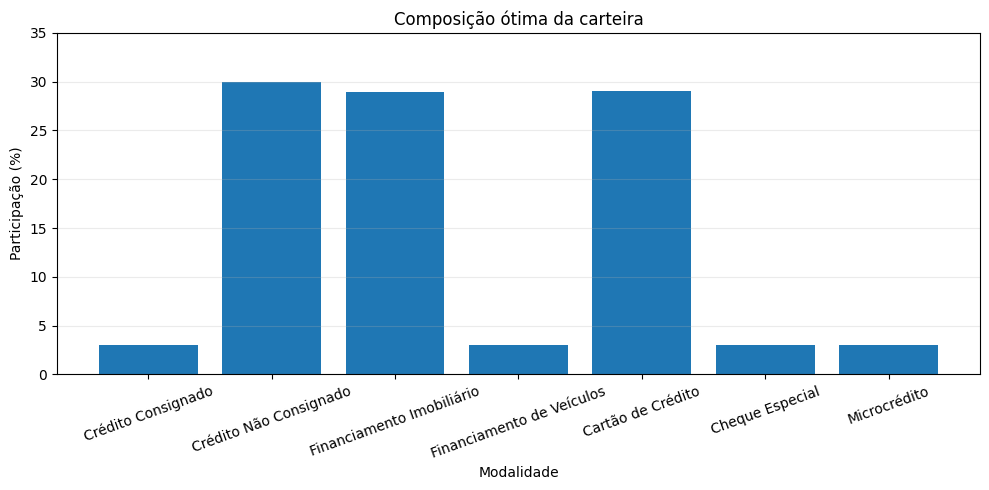

In [ ]:
summary_solution = pd.DataFrame({
    "Indicador": [
        "Status",
        "Retorno esperado da carteira",
        "Retorno mínimo",
        "Risco de inadimplência da carteira",
        "Risco máximo",
        "Soma das alocações",
    ],
    "Valor": [
        "Ótimo / factível",
        f"{portfolio_return:.3f}% a.a.",
        f"{CONFIG.capm_pct:.3f}% a.a.",
        f"{portfolio_risk:.3f}%",
        f"{CONFIG.risk_max_pct:.3f}%",
        f"{solution_df['alocacao_otima'].sum():.6f}",
    ]
})

display(summary_solution)

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(solution_df["modalidade"], solution_df["alocacao_otima_pct"])
ax.set_title("Composição ótima da carteira")
ax.set_xlabel("Modalidade")
ax.set_ylabel("Participação (%)")
ax.set_ylim(0, max(35, solution_df["alocacao_otima_pct"].max() + 5))
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()



## 6. Interpretação dos resultados

A composição ótima deve ser interpretada conjuntamente com os retornos, os riscos e as restrições.

Uma modalidade pode apresentar retorno elevado e, ainda assim, não receber grande participação na carteira caso seu risco seja alto. Da mesma forma, uma modalidade com retorno menor pode receber participação elevada quando contribui para manter a carteira dentro do limite de inadimplência.

Na solução encontrada a interpretação deve responder a três perguntas:

1. **Quais modalidades receberam maior participação?**
2. **Quais restrições ficaram ativas ou próximas de serem ativas?**
3. **A carteira supera o retorno mínimo sem ultrapassar o risco máximo?**

### Verificação de restrições ativas

Uma restrição é considerada ativa quando a solução está muito próxima do seu limite. Em um problema de maximização, essas restrições são especialmente importantes para compreender o formato da solução.


In [ ]:
def active_constraints(solution_df, config: ModelConfig, tolerance: float = 1e-6):
    rows = []

    total_alloc = solution_df["alocacao_otima"].sum()
    portfolio_risk = (
        solution_df["alocacao_otima"] * solution_df["risco_inadimplencia_pct"]
    ).sum()
    portfolio_return = (
        solution_df["alocacao_otima"] * solution_df["retorno_esperado_aa"]
    ).sum()

    rows.append({
        "restrição": "Alocação total",
        "valor": total_alloc,
        "limite": 1.0,
        "ativa": abs(total_alloc - 1.0) <= tolerance
    })
    rows.append({
        "restrição": "Risco máximo",
        "valor": portfolio_risk,
        "limite": config.risk_max_pct,
        "ativa": abs(portfolio_risk - config.risk_max_pct) <= 1e-5
    })
    rows.append({
        "restrição": "Retorno mínimo",
        "valor": portfolio_return,
        "limite": config.capm_pct,
        "ativa": abs(portfolio_return - config.capm_pct) <= 1e-5
    })

    for _, row in solution_df.iterrows():
        rows.append({
            "restrição": f"Mínimo - {row['modalidade']}",
            "valor": row["alocacao_otima"],
            "limite": config.min_allocation,
            "ativa": abs(row["alocacao_otima"] - config.min_allocation) <= tolerance
        })
        rows.append({
            "restrição": f"Máximo - {row['modalidade']}",
            "valor": row["alocacao_otima"],
            "limite": config.max_allocation,
            "ativa": abs(row["alocacao_otima"] - config.max_allocation) <= tolerance
        })

    return pd.DataFrame(rows)

active_df = active_constraints(solution_df, CONFIG)
display(active_df[active_df["ativa"]].round(6))


,restrição,valor,limite,ativa
0,Alocação total,1.00,1.00,True
1,Risco máximo,6.56,6.56,True
3,Mínimo - Crédito Consignado,0.03,0.03,True
6,Máximo - Crédito Não Consignado,0.30,0.30,True
9,Mínimo - Financiamento de Veículos,0.03,0.03,True
13,Mínimo - Cheque Especial,0.03,0.03,True
15,Mínimo - Microcrédito,0.03,0.03,True


## 7. Análise comparativa de cenários de otimização da carteira de crédito

Com o objetivo de avaliar a influência das restrições de alocação e do limite de risco sobre a composição e o desempenho da carteira de crédito, serão testados três cenários alternativos, cujos resultados serão comparados com o cenário original. A análise busca compreender como diferentes configurações do problema de otimização afetam o retorno esperado, o risco de inadimplência e a distribuição dos recursos entre as modalidades de crédito.

### Cenário 1 — Modelo original

O cenário original será utilizado como referência para as comparações. Nesse modelo, a otimização busca maximizar o retorno esperado da carteira, respeitando o retorno mínimo exigido pelo CAPM, o limite máximo de risco de inadimplência de 6,56% e as restrições de alocação por modalidade, estabelecidas entre 3% e 30% dos recursos disponíveis.

### Cenário 2 — Remoção dos limites de alocação

Neste cenário, serão removidas as restrições que determinam uma alocação mínima de 3% e máxima de 30% para cada modalidade de crédito. As proporções poderão variar entre 0% e 100% do capital disponível, mantendo-se a restrição de que a soma das alocações seja igual a 100%.

O objetivo continuará sendo maximizar o retorno esperado, respeitando o retorno mínimo estabelecido pelo CAPM e o limite original de risco de inadimplência. Essa configuração permitirá avaliar se os limites de concentração impostos pelo modelo original restringem a obtenção de retornos superiores e como sua remoção altera a distribuição dos recursos entre as modalidades.

### Cenário 3 — Ampliação do limite de risco

Neste cenário, será ampliado o limite máximo de risco de inadimplência, introduzindo-se uma variável denominada **delta de risco $\Delta_{\text{risco}}$**. O novo limite será calculado pela soma do risco máximo original com o delta definido para o experimento:

$
R_{\max}^{(3)} = R_{\max}^{(1)} + \Delta_{\text{risco}}
$

Como configuração inicial, será utilizado um delta de 2 pontos percentuais, elevando o limite de risco de 6,56% para 8,56%. As demais restrições serão mantidas, incluindo os limites de alocação entre 3% e 30% e o retorno mínimo exigido pelo CAPM.

Esse cenário permitirá investigar se uma maior tolerância ao risco de inadimplência proporciona ganhos de retorno esperado e quais modalidades de crédito passam a receber maior participação na carteira. Adicionalmente, a variação do delta poderá ser utilizada em uma análise de sensibilidade para avaliar a relação entre risco, retorno e composição da carteira.

### Cenário 4 — Minimização do risco de inadimplência

No quarto cenário, será alterada a função objetivo do problema de otimização. Em vez de maximizar o retorno esperado, o modelo buscará **minimizar o risco de inadimplência da carteira**, mantendo o retorno mínimo exigido pelo CAPM como restrição.

Serão preservados o limite máximo de risco de 6,56% e as restrições de alocação entre 3% e 30%. Dessa forma, o modelo buscará a combinação de modalidades que produza a menor inadimplência esperada possível sem comprometer o retorno mínimo exigido.

A comparação com o cenário original permitirá avaliar o custo, em termos de retorno esperado, de priorizar a redução do risco. Também será possível identificar quais modalidades ganham ou perdem participação quando o objetivo principal passa a ser a segurança da carteira, em vez da maximização do retorno.

### Critérios de comparação

Os quatro cenários serão avaliados utilizando os mesmos indicadores: retorno esperado da carteira, risco de inadimplência, factibilidade da solução e percentual de alocação destinado a cada modalidade de crédito.

A análise comparativa permitirá identificar os efeitos isolados da flexibilização das restrições de alocação, da ampliação do risco máximo e da mudança da função objetivo. Espera-se, assim, compreender os compromissos entre rentabilidade, risco e diversificação, oferecendo subsídios para a escolha de uma estratégia de alocação compatível com os objetivos e as restrições da instituição financeira.

In [ ]:
# ============================================================
# COMPARAÇÃO DOS 4 CENÁRIOS DE OTIMIZAÇÃO
# ============================================================

# Cenário 3: aumento do limite de risco em pontos percentuais.
DELTA_RISCO = 2.0

def criar_config(risk_max_pct, min_allocation, max_allocation):
    return ModelConfig(
        risk_max_pct=risk_max_pct,
        min_allocation=min_allocation,
        max_allocation=max_allocation,
        rf_pct=CONFIG.rf_pct,
        beta=CONFIG.beta,
        rm_pct=CONFIG.rm_pct,
        start_date=CONFIG.start_date,
        end_date=CONFIG.end_date,
    )


def resolver_cenario(parameters, config, objetivo="retorno"):
    """Resolve a carteira maximizando retorno ou minimizando risco."""

    retornos = parameters["retorno_esperado_aa"].to_numpy()
    riscos = parameters["risco_inadimplencia_pct"].to_numpy()
    n = len(parameters)

    if objetivo == "retorno":
        c = -retornos
    elif objetivo == "risco":
        c = riscos
    else:
        raise ValueError("Objetivo deve ser 'retorno' ou 'risco'.")

    resultado = linprog(
        c=c,
        A_ub=np.vstack([riscos, -retornos]),
        b_ub=np.array([
            config.risk_max_pct,
            -config.capm_pct,
        ]),
        A_eq=np.ones((1, n)),
        b_eq=np.array([1.0]),
        bounds=[
            (config.min_allocation, config.max_allocation)
            for _ in range(n)
        ],
        method="highs-ds",
    )

    if not resultado.success:
        return {
            "status": "Inviável",
            "config": config,
            "retorno": np.nan,
            "risco": np.nan,
            "alocacoes": None,
            "mensagem": resultado.message,
        }

    return {
        "status": "Ótimo",
        "config": config,
        "retorno": float(retornos @ resultado.x),
        "risco": float(riscos @ resultado.x),
        "alocacoes": pd.Series(
            resultado.x,
            index=parameters["modalidade"],
            name="alocacao",
        ),
        "mensagem": resultado.message,
    }


# ------------------------------------------------------------
# CENÁRIO 1 — Modelo original: maximizar retorno, limites 3%-30%
# ------------------------------------------------------------
config_1 = criar_config(
    CONFIG.risk_max_pct,
    CONFIG.min_allocation,
    CONFIG.max_allocation,
)

cenario_1 = resolver_cenario(parameters, config_1, "retorno")


# ------------------------------------------------------------
# CENÁRIO 2 — Maximizar retorno sem limites de 3%-30%
# ------------------------------------------------------------
config_2 = criar_config(
    CONFIG.risk_max_pct,
    0.0,
    1.0,
)

cenario_2 = resolver_cenario(parameters, config_2, "retorno")


# ------------------------------------------------------------
# CENÁRIO 3 — Maior risco permitido por meio de delta
# ------------------------------------------------------------
RISCO_MAX_CENARIO_3 = CONFIG.risk_max_pct + DELTA_RISCO

config_3 = criar_config(
    RISCO_MAX_CENARIO_3,
    CONFIG.min_allocation,
    CONFIG.max_allocation,
)

cenario_3 = resolver_cenario(parameters, config_3, "retorno")


# ------------------------------------------------------------
# CENÁRIO 4 — Minimizar risco mantendo o CAPM mínimo
# ------------------------------------------------------------
config_4 = criar_config(
    CONFIG.risk_max_pct,
    CONFIG.min_allocation,
    CONFIG.max_allocation,
)

cenario_4 = resolver_cenario(parameters, config_4, "risco")


resultados = {
    "1. Original": cenario_1,
    "2. Sem limites": cenario_2,
    "3. Risco + delta": cenario_3,
    "4. Menor risco": cenario_4,
}


# ============================================================
# TABELA COMPARATIVA
# ============================================================

resumo = pd.DataFrame([
    {
        "Cenário": nome,
        "Status": c["status"],
        "Retorno (% a.a.)": c["retorno"],
        "Risco da carteira (%)": c["risco"],
        "Risco máximo (%)": c["config"].risk_max_pct,
        "CAPM mínimo (%)": c["config"].capm_pct,
    }
    for nome, c in resultados.items()
])

display(resumo.round(3))

,Cenário,Status,Retorno (% a.a.),Risco da carteira (%),Risco máximo (%),CAPM mínimo (%)
0,1. Original,Ótimo,56.902,6.560,6.56,19.282
1,2. Sem limites,Ótimo,68.293,6.560,6.56,19.282
2,3. Risco + delta,Ótimo,74.094,8.560,8.56,19.282
3,4. Menor risco,Ótimo,21.851,3.779,6.56,19.282


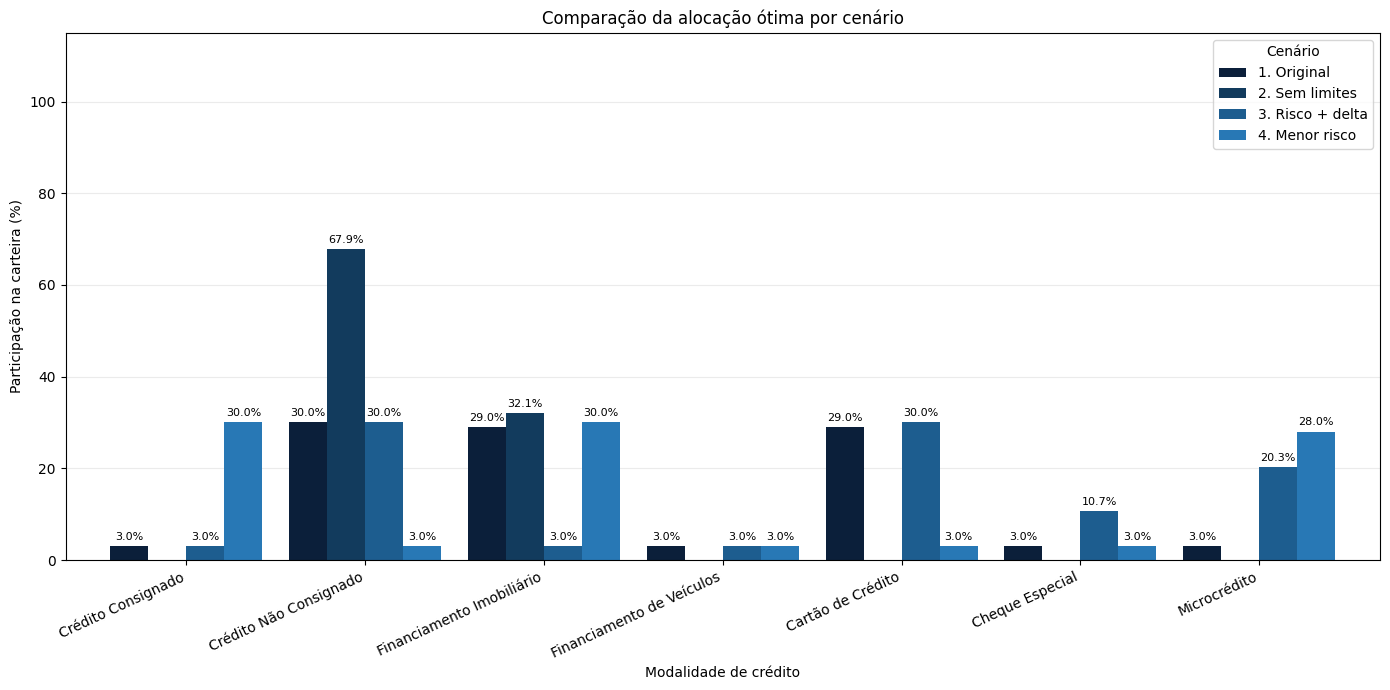

,1. Original,2. Sem limites,3. Risco + delta,4. Menor risco
modalidade,,,,
Crédito Consignado,3.00,0.0,3.00,30.0
Crédito Não Consignado,30.00,67.9,30.00,3.0
Financiamento Imobiliário,28.96,32.1,3.00,30.0
Financiamento de Veículos,3.00,0.0,3.00,3.0
Cartão de Crédito,29.04,0.0,30.00,3.0
Cheque Especial,3.00,0.0,10.69,3.0
Microcrédito,3.00,0.0,20.31,28.0


In [ ]:

# ============================================================
# GRÁFICO DE ALOCAÇÃO DOS RECURSOS
# ============================================================
# Paleta de tons de azul
paleta_azul = [
    "#0B1F3A",  # Azul-marinho
    "#123B5D",  # Azul escuro
    "#1D5D8F",  # Azul médio escuro
    "#2878B5",  # Azul médio
    "#4A9AD4",  # Azul
    "#78B7E0",  # Azul claro
    "#A6D4ED",  # Azul bem claro
    "#C9E5F5",  # Azul gelo
]


alocacoes_validas = {
    nome: c["alocacoes"]
    for nome, c in resultados.items()
    if c["alocacoes"] is not None
}

if alocacoes_validas:
    comparacao_alocacao = pd.DataFrame(alocacoes_validas) * 100

    ax = comparacao_alocacao.plot(
    kind="bar",
    figsize=(14, 7),
    width=0.85,
    color=paleta_azul[:len(comparacao_alocacao.columns)]
)

    # Adiciona os percentuais em cada barra
    for container in ax.containers:
        labels = [
            f"{barra.get_height():.1f}%"
            if barra.get_height() > 0
            else ""
            for barra in container
        ]

        ax.bar_label(
            container,
            labels=labels,
            padding=3,
            fontsize=8,
            rotation=0,
        )

    ax.set_title("Comparação da alocação ótima por cenário")
    ax.set_xlabel("Modalidade de crédito")
    ax.set_ylabel("Participação na carteira (%)")
    ax.set_ylim(0, 115)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
    ax.legend(title="Cenário")

    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()

    display(comparacao_alocacao.round(2))
else:
    print("Nenhum cenário encontrou uma solução factível.")



**Interpretação:**<br/>
 - Cenário 1: Equilibra bem a distribuição da carteira mas utiliza apenas 3 modalidades 30% em Crédito Não Consignado, 29% em Financiamento Imobiliário, e 29% em Cartão de Crédito, os demais produtos ficam na alocação mínima de 3%.

 - Cenário 2: Removendo o limite de alocação vemos que a composição da carteira vai toda para Crédito Não Consignado com 68% e Financiamento Imobiliário com 32% e esse cenário tem a vantagem de aumentar o retorno ao ano de 58% para 70%.

 - Cenário 3: Muda a forma de otimização e tenta maximizar a distancia entre o CAPM e o risco, no fim ele permite um aumento no risco em troca de um retorno maior, aqui é onde tivemos uma utilização relevante do Microcrédito e Cheque Especial, entretanto Financiamento Imobiliário ficou com a alocação mínima, a aposta foi em produtos de mais risco gerando um retorno de 74% ao ano vs 8.5% de risco.

 - Cenário 4: O foco desse cenário é minimizar o risco e ele consegue derrubando de 6.5% para 3.7%, mas o retorno cai drasticamente para 23% ao ano, a composição da carteira foca em Microcrédito, e depois opta por dois produtos de baixo risco Crédito Consignado e Financiamento Imobiliário, os demais ítens da carteira ficam com a alocação mínima.

#8.  Análise de Sensibilidade

Medimos o efeito das mudanças nos indicadores sobre a carteira atual. Além disso, pressupõe que a selic e o retorno possam ser tratados como indicadores variados.

- Se a Selic aumenta, o spread diminui: o retorno tende a diminuir
- Se a Selic diminui, o spread aumenta: o retorno tende a aumentar
- Inadimplência menor: a modalidade pode ficar mais atrativa, pois oferece menor risco, retorno maior. (considerando a restrição até 6.56%)
- Inadimplência maior: a modalidade pode perder atratividade e receber uma alocação menor de recursos, retorno menor. (considerando a restrição até 6.56%)


In [ ]:

import pandas as pd
mudanca_inad = 1  #valor que vai multiplicar
mudanca_selic= 2  #valor que vai multiplicar

df_new = generate_synthetic_credit_data(CONFIG)

parameters_new = build_model_parameters(df_new)

df_new = parameters_new.copy()

# Cenário: inadimplência aumenta 1 ponto percentual
df_new["risco_inadimplencia_pct_novo"] = (
    df_new["risco_inadimplencia_pct"] * mudanca_inad
)

# O cenário da selic já está puxando da função generate_synthetic_credit_data
parameters_new = (
    df_new[
        [
            "modalidade",
            "retorno_esperado_aa",
            "risco_inadimplencia_pct_novo",
            "taxa_juros_media_aa",
        ]
    ]
    .rename(
        columns={
            "risco_inadimplencia_pct_novo":
                "risco_inadimplencia_pct"
        }
    )
    .round(4)
)

display(parameters_new)


result_new = solve_credit_portfolio(parameters_new, CONFIG)

print("Status do solver:", result_new.message)
assert result_new.success, "O problema não encontrou uma solução factível."

print(f"Valor da função objetivo: {-result_new.fun:.4f}% a.a.")
solution_df_new = build_solution_table(parameters_new, result_new.x)

portfolio_return_new = solution_df_new["contrib_retorno_pct"].sum()
portfolio_risk_new = solution_df_new["contrib_risco_pct"].sum()

display(
    solution_df_new[
        [
            "modalidade",
            "retorno_esperado_aa",
            "risco_inadimplencia_pct",
            "alocacao_otima_pct",
            "contrib_retorno_pct",
            "contrib_risco_pct",
        ]
    ].round(3)
)
# Inadimplência ponderada da carteira
inadimplencia_ponderada = (
    solution_df_new["risco_inadimplencia_pct"]
    * solution_df_new["alocacao_otima"]
).sum()


print(f"Retorno da carteira: {portfolio_return_new:.3f}% a.a.")
print(f"Risco da carteira: {portfolio_risk_new:.3f}%")


,modalidade,retorno_esperado_aa,risco_inadimplencia_pct,taxa_juros_media_aa
0,Crédito Consignado,-1.5067,2.81,27.16
1,Crédito Não Consignado,87.9233,9.16,116.59
2,Financiamento Imobiliário,-17.8867,1.06,10.78
3,Financiamento de Veículos,-2.2267,5.69,26.44
4,Cartão de Crédito,60.5133,8.89,89.18
5,Cheque Especial,110.2233,17.33,138.89
6,Microcrédito,20.1533,4.95,48.82


Status do solver: Optimization terminated successfully. (HiGHS Status 7: Optimal)
Valor da função objetivo: 42.5690% a.a.


,modalidade,retorno_esperado_aa,risco_inadimplencia_pct,alocacao_otima_pct,contrib_retorno_pct,contrib_risco_pct
0,Crédito Consignado,-1.507,2.81,3.00,-0.045,0.084
1,Crédito Não Consignado,87.923,9.16,30.00,26.377,2.748
2,Financiamento Imobiliário,-17.887,1.06,28.96,-5.180,0.307
3,Financiamento de Veículos,-2.227,5.69,3.00,-0.067,0.171
4,Cartão de Crédito,60.513,8.89,29.04,17.573,2.582
5,Cheque Especial,110.223,17.33,3.00,3.307,0.520
6,Microcrédito,20.153,4.95,3.00,0.605,0.148


Retorno da carteira: 42.569% a.a.
Risco da carteira: 6.560%


In [ ]:

import pandas as pd

# ============================================================
# CENÁRIOS DE SENSIBILIDADE
# ============================================================

cenarios = [
     ("Selic", "Base", 1.00),
     ("Selic", "Queda de 10%", 0.90),
    ("Selic", "Aumento de 10%", 1.10),
   # ("Selic", "Aumento de 20%", 1.20),

   # ("Inadimplência", "Queda de 20%", 0.80),
    ("Inadimplência", "Queda de 10%", 0.9),
    ("Inadimplência", "Aumento de 10%", 1.1),
   # ("Inadimplência", "Aumento de 20%", 1.20),
]

resultados = []

# ============================================================
# EXECUTAR CADA SIMULAÇÃO
# ============================================================

for fator_alterado, cenario, fator in cenarios:

    # Mantém o outro fator no valor-base
    mudanca_selic = fator if fator_alterado == "Selic" else 1.0
    mudanca_inad = fator if fator_alterado == "Inadimplência" else 1.0

    # Gera os dados do cenário
    df_new_sensib = generate_synthetic_credit_data(CONFIG)

    parameters_new_sensib = build_model_parameters(df_new_sensib)
    df_new_sensib = parameters_new_sensib.copy()

    # Aplica a variação da inadimplência
    df_new_sensib["risco_inadimplencia_pct_novo"] = (
        df_new_sensib["risco_inadimplencia_pct"] * mudanca_inad
    )

    parameters_new_sensib = (
        df_new_sensib[
            [
                "modalidade",
                "retorno_esperado_aa",
                "risco_inadimplencia_pct_novo",
                "taxa_juros_media_aa",
            ]
        ]
        .rename(
            columns={
                "risco_inadimplencia_pct_novo":
                    "risco_inadimplencia_pct"
            }
        )
        .round(4)
    )

    # Resolve a carteira ótima
    result_new_sensib = solve_credit_portfolio(parameters_new_sensib, CONFIG)

    if not result_new_sensib.success:
        resultados.append({
            "Fator": fator_alterado,
            "Cenário": cenario,
            "Multiplicador": fator,
            "Retorno da carteira (% a.a.)": None,
            "Risco da carteira (%)": None
        })
        continue

    solution_df_new_sensib = build_solution_table(
        parameters_new_sensib,
        result_new_sensib.x
    )

    portfolio_return_new_sensib = (
        solution_df_new_sensib["contrib_retorno_pct"].sum()
    )
    portfolio_risk_new_sensib = (
        solution_df_new_sensib["contrib_risco_pct"].sum()
    )
    # Inadimplência ponderada da carteira

    inadimplencia_ponderada = (
    solution_df_new_sensib["risco_inadimplencia_pct"]
    * solution_df_new_sensib["alocacao_otima"]
).sum()


    resultados.append({
        "Fator": fator_alterado,
        "Cenário": cenario,
        "Multiplicador": fator,
        "Retorno da carteira (% a.a.)": portfolio_return_new_sensib,
        "Risco da carteira (%)": portfolio_risk_new_sensib,
        "Inadimplência Ponderada": inadimplencia_ponderada
    })

# ============================================================
# TABELA FINAL COM VARIAÇÃO DO RETORNO
# ============================================================

tabela_final = pd.DataFrame(resultados)

display(tabela_final)


,Fator,Cenário,Multiplicador,Retorno da carteira (% a.a.),Risco da carteira (%),Inadimplência Ponderada
0,Selic,Base,1.0,56.902440,6.56,6.56
1,Selic,Queda de 10%,0.9,58.335740,6.56,6.56
2,Selic,Aumento de 10%,1.1,55.469040,6.56,6.56
3,Inadimplência,Queda de 10%,0.9,64.047772,6.56,6.56
4,Inadimplência,Aumento de 10%,1.1,50.834432,6.56,6.56
